# Lab 1-01：文字怎麼變成 token

**目標**：用兩個真實的切詞器（OpenAI 的 `tiktoken`、Qwen 的 Hugging Face tokenizer）把同一段文字切開，
看模型實際收到什麼、中英文差多少、一段文字要花多少錢。

**你會學到**
- 模型看到的不是字，是一串整數（token id）
- 不同模型的詞表不同，同一句話切出來的 token 數也不同
- 中英文的 token 成本怎麼比、怎麼用 token 數估費用
- 對話格式（chat template）本身也會吃 token

**前置**：先讀 `00_concepts.md` 第 1 節（token 與 BPE）。會用到 tiktoken 的詞表（約 3MB）和 `Qwen/Qwen2.5-0.5B` 的 tokenizer（Lab 1-02、1-03 也會用同一個模型）。

**對應投影片**：「文字切成 token」「詞表與切分粒度」

![同一句話被切成幾格 token：英文 5 格、中文 7 格](images/token_strip.jpg)

*圖：每一格是一個 token，上方的小數字是第幾格。每一格在詞表裡都有一個編號（token id），模型只看得到那串編號；中文常常一個字就是一格，甚至一個字被切成兩格（Step 2 會看到）。*

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import tiktoken
from transformers import AutoTokenizer

from course_utils.viz import setup_cjk

setup_cjk()

'Noto Sans CJK TC'

## Step 1：用 tiktoken 切一句話

`tiktoken` 是 OpenAI 的切詞器，`o200k_base` 是 GPT-4o 之後的模型用的詞表（約 20 萬個 token）。
`encode` 把文字變成 id，`decode` 再變回來。

In [2]:
gpt = tiktoken.get_encoding("o200k_base")

text = "魯夫想成為海賊王。"
ids = gpt.encode(text)
print("token id：", ids)
print("每個 id 對應的片段：", [gpt.decode([i]) for i in ids])
print("解回來：", gpt.decode(ids))
print("詞表大小：", gpt.n_vocab)

token id： [32937, 107, 31050, 18165, 5543, 54271, 12426, 17583, 232, 15881, 788]
每個 id 對應的片段： ['�', '�', '夫', '想', '成', '為', '海', '�', '�', '王', '。']
解回來： 魯夫想成為海賊王。
詞表大小： 200019


## Step 2：換 Qwen 的切詞器

開放權重模型的切詞器跟權重一起放在 Hugging Face 上，用 `AutoTokenizer` 一行載入。
同一句話，詞表不同，切法就不同。

In [3]:
qwen = AutoTokenizer.from_pretrained("Qwen/Qwen2.5-0.5B")

ids = qwen(text).input_ids
print("token id：", ids)
print("每個 id 對應的片段：", [qwen.decode([i]) for i in ids])
print("詞表大小：", len(qwen))

token id： [115571, 99818, 99172, 106027, 55135, 82712, 232, 99445, 1773]
每個 id 對應的片段： ['魯', '夫', '想', '成為', '海', '�', '�', '王', '。']
詞表大小： 151665


注意那些 `�`：「賊」這個字不在 Qwen 的詞表裡，被拆成兩個 token，每個只是這個字的一部分 byte，單獨解不出字來。
回頭看 Step 1，GPT 的詞表連「魯」也拆成兩格；反過來，Qwen 把「成為」合成一格，GPT 則是「成」「為」各一格。
這就是 byte-level BPE：任何文字最後都能退回 byte，所以永遠切得了，只是罕見字要多花幾格。

## Step 3：點開看——詞表裡的合併規則

BPE 的詞表是「統計哪兩個片段最常相鄰，就合併成一個新 token」重複十幾萬次得到的（原理見 `00_concepts.md`）。
Qwen 的 tokenizer 把這份合併規則存在裡面，我們直接印出來看，不用自己重寫一遍。

In [4]:
import json

bpe = json.loads(qwen.backend_tokenizer.to_str())["model"]
print("演算法：", bpe["type"], "，合併規則數：", len(bpe["merges"]))
print("最早學到的 8 條：", bpe["merges"][:8])

演算法： BPE ，合併規則數： 151387
最早學到的 8 條： [['Ġ', 'Ġ'], ['ĠĠ', 'ĠĠ'], ['i', 'n'], ['Ġ', 't'], ['ĠĠĠĠ', 'ĠĠĠĠ'], ['e', 'r'], ['ĠĠ', 'Ġ'], ['o', 'n']]


`Ġ` 代表空白。最早學到的合併是「兩個空白」「i＋n」「空白＋t」：都是英文語料裡最常見的組合。
越早學到的合併越優先；中文常用詞因為語料比例少，排在後面，罕見字甚至沒被合併到。

## Step 4：中文比英文貴多少？

拿幾組意思相同的中英文句子，用兩個切詞器各數一次。

In [5]:
pairs = [
    ("魯夫的夢想是成為海賊王。", "Luffy's dream is to become the King of the Pirates."),
    ("索隆想成為世界第一的劍豪。", "Zoro wants to become the world's greatest swordsman."),
    ("娜美想畫出全世界的地圖。", "Nami wants to draw a map of the whole world."),
    ("請幫我查詢付款服務最近一小時的錯誤日誌。", "Please check the payment service error logs for the last hour."),
    ("把這份會議紀錄整理成三點摘要。", "Summarize these meeting notes into three bullet points."),
]

rows = []
for zh, en in pairs:
    rows.append({
        "zh_gpt": len(gpt.encode(zh)), "en_gpt": len(gpt.encode(en)),
        "zh_qwen": len(qwen(zh).input_ids), "en_qwen": len(qwen(en).input_ids),
        "zh_chars": len(zh),
    })
    print(f"{zh}\n  中文 {len(zh)} 字 → GPT {rows[-1]['zh_gpt']} / Qwen {rows[-1]['zh_qwen']} token；"
          f"英文 → GPT {rows[-1]['en_gpt']} / Qwen {rows[-1]['en_qwen']} token")

魯夫的夢想是成為海賊王。
  中文 12 字 → GPT 14 / Qwen 12 token；英文 → GPT 13 / Qwen 13 token
索隆想成為世界第一的劍豪。
  中文 13 字 → GPT 12 / Qwen 9 token；英文 → GPT 11 / Qwen 12 token
娜美想畫出全世界的地圖。
  中文 12 字 → GPT 11 / Qwen 9 token；英文 → GPT 12 / Qwen 12 token
請幫我查詢付款服務最近一小時的錯誤日誌。
  中文 20 字 → GPT 19 / Qwen 15 token；英文 → GPT 12 / Qwen 12 token
把這份會議紀錄整理成三點摘要。
  中文 15 字 → GPT 13 / Qwen 11 token；英文 → GPT 11 / Qwen 11 token


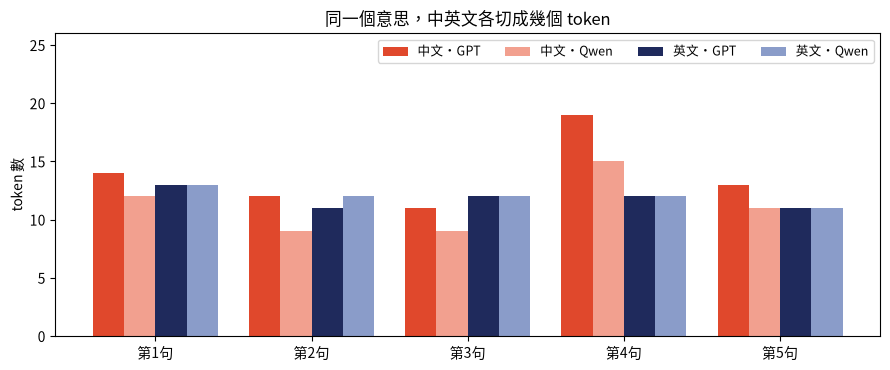

In [6]:
labels = [f"第{i + 1}句" for i in range(len(rows))]
x = range(len(rows))
w = 0.2
fig, ax = plt.subplots(figsize=(9, 3.8))
for k, (key, name, color) in enumerate([
    ("zh_gpt", "中文・GPT", "#e0482c"), ("zh_qwen", "中文・Qwen", "#f2a08f"),
    ("en_gpt", "英文・GPT", "#1f2a5c"), ("en_qwen", "英文・Qwen", "#8a9cc9"),
]):
    ax.bar([i + (k - 1.5) * w for i in x], [r[key] for r in rows], width=w, label=name, color=color)
ax.set_xticks(list(x), labels)
ax.set_ylabel("token 數")
ax.set_ylim(0, max(max(r.values()) for r in rows) * 1.3)  # 留空間給圖例
ax.set_title("同一個意思，中英文各切成幾個 token")
ax.legend(ncol=4, fontsize=9)
plt.tight_layout()
plt.show()

這幾句的結果：中文的 token 數跟英文差不多，有時明顯更多（第 4 句：中文 19 對英文 12，GPT），有時更少（Qwen 的第 2、3 句）。
英文一個常見單字通常就是一格；中文常常一個字一格，罕見字還會拆成兩格，常用詞才合成一格。
Qwen 的訓練語料中文比例高，詞表收了比較多中文詞，所以切得比 GPT 少。結論：**不能用字數估，要用該模型自己的切詞器數**。

## Step 5：數 token 估費用

雲端 API 按 token 收費，輸入和輸出的單價不同。下面用一份**假設的**價目表（每百萬 token 美元）示範怎麼估；實際價格以各家官方定價頁為準。

In [7]:
corpus = Path("data/one_piece.txt").read_text(encoding="utf-8")
n_in = len(gpt.encode(corpus))
print(f"語料 {len(corpus)} 個字元 → {n_in} 個 token（o200k_base）")

PRICE = {"小模型": (0.10, 0.40), "中模型": (1.00, 4.00), "大模型": (5.00, 20.00)}  # 假設價格：(輸入, 輸出)
calls_per_day, out_tokens = 1_000, 300
for name, (p_in, p_out) in PRICE.items():
    per_call = n_in / 1e6 * p_in + out_tokens / 1e6 * p_out
    print(f"{name}：每次約 ${per_call:.5f}，一天 {calls_per_day} 次約 ${per_call * calls_per_day:.2f}，一個月約 ${per_call * calls_per_day * 30:.0f}")

語料 523 個字元 → 300 個 token（o200k_base）
小模型：每次約 $0.00015，一天 1000 次約 $0.15，一個月約 $4
中模型：每次約 $0.00150，一天 1000 次約 $1.50，一個月約 $45
大模型：每次約 $0.00750，一天 1000 次約 $7.50，一個月約 $225


每次幾毫美分看起來很便宜，乘上呼叫次數就不是了。後面做 RAG 和 agent 時，「塞進 prompt 的東西有多長」會直接變成帳單。

## Step 6：對話格式也吃 token

你送出的 `messages` 不是原封不動交給模型的：伺服器會先用 **chat template** 把它攤平成一段文字，加上角色標記。
Qwen 的 tokenizer 裡就帶著這份模板，可以直接看攤平後的樣子。

In [8]:
messages = [
    {"role": "system", "content": "你是航海士。"},
    {"role": "user", "content": "下一座島在哪？"},
]
flat = qwen.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
print(flat)
content_tokens = sum(len(qwen(m["content"]).input_ids) for m in messages)
total_tokens = len(qwen(flat).input_ids)
print(f"內容本身 {content_tokens} token，攤平後 {total_tokens} token")

<|im_start|>system
你是航海士。<|im_end|>
<|im_start|>user
下一座島在哪？<|im_end|>
<|im_start|>assistant

內容本身 9 token，攤平後 22 token


`<|im_start|>`、`<|im_end|>` 是特殊 token，告訴模型「這段是誰說的」。最後那行 `<|im_start|>assistant` 就是在請模型接著往下寫。
這也說明了 `00_concepts.md` 講的：模型從頭到尾只做「接下去寫」這件事，對話只是一種排版。

## Step 7：三個實務後果

In [9]:
for s in ["strawberry", "1234567890", "3.14159", "2026-11-18"]:
    print(f"{s:12s} GPT →", [gpt.decode([t]) for t in gpt.encode(s)],
          "  Qwen →", [qwen.decode([t]) for t in qwen(s).input_ids])

strawberry   GPT → ['st', 'raw', 'berry']   Qwen → ['str', 'aw', 'berry']
1234567890   GPT → ['123', '456', '789', '0']   Qwen → ['1', '2', '3', '4', '5', '6', '7', '8', '9', '0']
3.14159      GPT → ['3', '.', '141', '59']   Qwen → ['3', '.', '1', '4', '1', '5', '9']
2026-11-18   GPT → ['202', '6', '-', '11', '-', '18']   Qwen → ['2', '0', '2', '6', '-', '1', '1', '-', '1', '8']


1. **計費與 context 上限都按 token 算**：同樣的意思，換一個模型、換一種語言，token 數就不一樣。
2. **模型看不到字母**：GPT 看到的是 `st` `raw` `berry`、Qwen 看到的是 `str` `aw` `berry`，所以「strawberry 有幾個 r」容易錯。
3. **數字被切得很碎**：兩家切法還不一樣（GPT 三位一組、Qwen 一位一格），這是模型算術不穩的原因之一；要算數就交給工具（模組 5）。

## 試試看

1. 把你最常寫的一段 prompt 貼進 Step 5，算出它在三種價位下一個月要多少錢。
2. 在 Step 4 加一組含有程式碼或 JSON 的句子，看看符號多的文字切起來怎樣。
3. 在 Step 6 的 `messages` 多加三輪對話，觀察「攤平後」比「內容本身」多出多少 token。

## 小結

- 模型的輸入是一串 token id；切法由詞表決定，詞表是 BPE 統計出來的。
- 罕見字、數字切得特別碎；同一段文字在不同模型上的 token 數不同，估費用要用該模型自己的切詞器數。
- 下一本：這些 tokenizer 和模型是從 Hugging Face 下載的——先認識這個平台和它的函式庫，再看模型怎麼猜下一個 token。